## Roblox Discovery Analysis

- Starting Hypothesis:
  - Players struggle to find new, high-quality experiences
  because discovery surfaces favor games that are already popular.


In [1]:
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

files = sorted(glob.glob("../data/raw/games_*.csv"))
raw = pd.concat([pd.read_csv(f) for f in files], ignore_index=True)
print(len(files), "pulls,", raw.shape)
raw.head()

3 pulls, (2650, 13)


,universe_id,rootPlaceId,name,genre,playing,visits,favoritedCount,maxPlayers,created,updated,upVotes,downVotes,pulled_at_utc
0,6331902150,18687417158,[UPD 🤖] Forsaken,All,80939,5844951987,3259881,9,2024-07-28T02:20:42.22Z,2026-10-17T17:46:23.495Z,2405873,443359,2026-10-18T21:19:23.660898+00:00
1,5203828273,15101393044,[🎃] Dress To Impress,All,146282,11184301381,7628287,13,2023-10-18T09:11:36.563Z,2026-10-18T21:09:23.484Z,4040475,420625,2026-10-18T21:19:23.660898+00:00
2,10765288803,114326934417838,Break and Steal an Egg,All,80856,176786084,539610,7,2026-09-05T18:30:02.346Z,2026-10-18T19:11:20.205Z,327447,8136,2026-10-18T21:19:23.660898+00:00
3,3647333358,9872472334,[🎃HLWN] Evade,Horror,51335,9333350378,8476821,15,2022-06-10T19:20:37.097Z,2026-10-18T18:34:42.597Z,3261610,212055,2026-10-18T21:19:23.660898+00:00
4,10767386157,103363457515322,🪵Chop A Forest,All,37868,14608760,53758,18,2026-09-21T12:02:18.72Z,2026-10-18T21:18:20.548Z,19086,1539,2026-10-18T21:19:23.660898+00:00


In [2]:
latest = raw.sort_values("pulled_at_utc").groupby("universe_id").last()
avg_playing = raw.groupby("universe_id")["playing"].mean().rename("avg_playing")
pulls_seen = raw.groupby("universe_id").size().rename("pulls_seen")
games = latest.join(avg_playing).join(pulls_seen).reset_index()
print(games.shape)

(942, 15)


In [3]:
games["created"] = pd.to_datetime(games["created"], utc=True, format="ISO8601")
games["updated"] = pd.to_datetime(games["updated"], utc=True, format="ISO8601")
pull_date = pd.to_datetime(raw["pulled_at_utc"], utc=True, format="ISO8601").max()

games["age_days"] = (pull_date - games["created"]).dt.days
games["days_since_update"] = (pull_date - games["updated"]).dt.days
games["total_votes"] = games["upVotes"] + games["downVotes"]
games["like_ratio"] = games["upVotes"] / games["total_votes"]
games["age_group"] = pd.cut(
    games["age_days"],
    bins=[-1, 182, 365, 730, np.inf],
    labels=["<6 mo", "6–12 mo", "1–2 yrs", "2+ yrs"],
)
games[["name", "avg_playing", "age_days", "like_ratio", "age_group"]].head(10).round({"avg_playing": 0, "like_ratio": 3})

,name,avg_playing,age_days,like_ratio,age_group
0,🍕Work at a Pizza Place,3719.0,6779,0.929,2+ yrs
1,Natural Disaster Survival,8306.0,6779,0.908,2+ yrs
2,🌳 Lumber Tycoon 2,3248.0,6290,0.877,2+ yrs
3,🎃 Notoriety: A PAYDAY® Experience,2278.0,6107,0.925,2+ yrs
4,Pilot Training Flight Simulator,3515.0,6132,0.933,2+ yrs
5,Murder Mystery 2,502402.0,4657,0.908,2+ yrs
6,Prison Life,6739.0,4554,0.850,2+ yrs
7,🔨Plane Crazy🔨 [UPDATE],4408.0,4478,0.802,2+ yrs
8,[🎃] Speed Run 4,814.0,4382,0.738,2+ yrs
9,[🌻GREEN HILL] Survive The Disasters 2,25.0,4402,0.887,2+ yrs


In [4]:
print(games["genre"].value_counts())

genre
All              746
Adventure         55
Fighting          34
Town and City     28
Horror            21
RPG               13
Sports            10
Military          10
Building           9
FPS                7
Comedy             6
Sci-Fi             1
Medieval           1
Naval              1
Name: count, dtype: int64


In [5]:
pl_all = pd.concat([pd.read_csv(f) for f in glob.glob("../data/raw/placements_*.csv")])

genre_rows = pl_all[pl_all["sort_name"].str.startswith("Trending in", na=False)].copy()
genre_rows["genre_label"] = genre_rows["sort_name"].str.replace("Trending in ", "", regex=False)

best = (genre_rows.sort_values("position")
        .drop_duplicates("universe_id")[["universe_id", "genre_label"]])

games = games.merge(best, on="universe_id", how="left")
games["genre_label"] = games["genre_label"].fillna("Unlabeled")
print(games["genre_label"].value_counts())

games.to_csv("../data/clean/games.csv", index=False)

genre_label
Unlabeled                445
Simulation                81
Survival                  38
Action                    36
Adventure                 34
Shopping                  33
Obby & Platformer         32
Strategy                  32
Party & Casual            31
Sports & Racing           31
RPG                       31
Roleplay & Avatar Sim     30
Entertainment             30
Shooter                   29
Puzzle                    29
Name: count, dtype: int64


In [6]:
games.groupby(games["genre_label"] == "Unlabeled")["avg_playing"].median()

genre_label
False    3839.666667
True      341.666667
Name: avg_playing, dtype: float64

Roblox's genre field was majority "All" for 746 of the 942 games in the dataset so I labeled genres using the "Trending in" charts. 497 games received a genre and 445 did not. Unlabeled games are much smaller in player count, so the genre analysis mainly describes the more popular games.

## Question 1:
How concentrated are players?

In [7]:
g = games.sort_values("avg_playing", ascending=False).reset_index(drop=True)
total = g["avg_playing"].sum()
for n in [10, 50, 100]:
    print(f"Top {n}: {g['avg_playing'].head(n).sum() / total:.1%} of players")

# Gini coefficient: 0 = perfectly equal, 1 = one game has everyone
x = np.sort(g["avg_playing"].values)
n = len(x)
gini = (2 * np.sum(np.arange(1, n + 1) * x) / (n * x.sum())) - (n + 1) / n
print(f"Gini: {gini:.2f}")

Top 10: 38.0% of players
Top 50: 61.3% of players
Top 100: 72.2% of players
Gini: 0.81


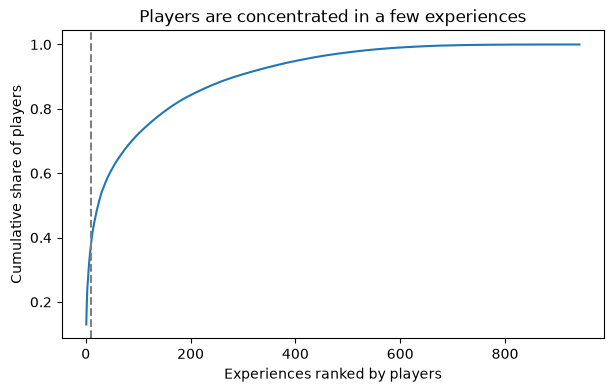

In [8]:
g["cum_share"] = g["avg_playing"].cumsum() / total
plt.figure(figsize=(7, 4))
plt.plot(range(1, len(g) + 1), g["cum_share"])
plt.axvline(10, linestyle="--", color="gray")
plt.xlabel("Experiences ranked by players")
plt.ylabel("Cumulative share of players")
plt.title("Players are concentrated in a few experiences")
plt.show()


Players are highly concentrated. The top 10 of 942 games hold 38% of all players, the top 100 hold 72%, and the Gini coefficient is 0.81. A small number of experiences capture most of the attention.

## Question 2:
How old are the experiences people play?

In [9]:
share_by_age = games.groupby("age_group", observed=False)["avg_playing"].sum() / total
print(share_by_age.round(3))

top50 = g.head(50)
print("Median age, top 50 (years):", round(top50["age_days"].median() / 365, 1))
print("Median age, everyone else (years):", round(g.iloc[50:]["age_days"].median() / 365, 1))
print("Games under 6 months old in the top 50:", (top50["age_days"] < 182).sum())

age_group
<6 mo      0.388
6–12 mo    0.047
1–2 yrs    0.120
2+ yrs     0.445
Name: avg_playing, dtype: float64
Median age, top 50 (years): 2.3
Median age, everyone else (years): 1.4
Games under 6 months old in the top 50: 16


Newer games can break through on Roblox's charts with 38.8% of players are playing games created in 6 months or less. Games created over 2 years old still have the highest share of players of 44.5%. This contradicts my hypothesis that discovery mainly favors old games.

## Question 3:
Which genres dominate, and which are underserved?

In [10]:
labeled = games[games["genre_label"] != "Unlabeled"]
genre_col = "genre_label"
by_genre = labeled.groupby(genre_col).agg(
    n_games=("universe_id", "count"),
    players=("avg_playing", "sum"),
    median_like=("like_ratio", "median"),
).sort_values("players", ascending=False)
by_genre["player_share"] = by_genre["players"] / total
by_genre.round(3)

,n_games,players,median_like,player_share
genre_label,,,,
Simulation,81,2328657.667,0.925,0.302
Survival,38,1319928.833,0.908,0.171
Roleplay & Avatar Sim,30,982773.000,0.887,0.128
Action,36,582562.667,0.874,0.076
RPG,31,348467.167,0.944,0.045
Shooter,29,344640.167,0.910,0.045
Sports & Racing,31,298384.667,0.877,0.039
Strategy,32,202058.667,0.907,0.026
Party & Casual,31,156776.000,0.810,0.020


Among the 497 labeled games from the “Trending in” Charts rows, Simulation has the largest share of all players (30%), followed by Survival (17%) and Roleplay & Avatar Sim (13%). Role-playing games (RPG) have the highest median like ratio (0.944) but only 4.5% of players, which makes RPG a possible underserved genre. Each “Trending in” row holds a similar number of games, except Simulation (81 vs. about 30 for the others), so I compare genres by players and ratings, not game counts.

## Question 4:
Are well-liked games being under-discovered?

942 → 921 games after the 500-vote filter


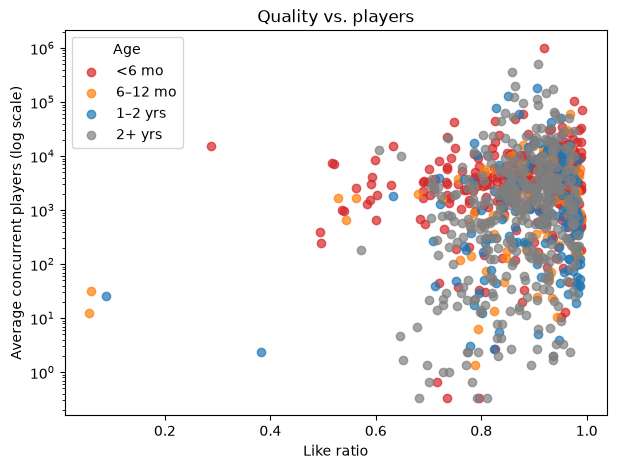

In [11]:
rated = games[games["total_votes"] >= 500].copy()
print(len(games), "→", len(rated), "games after the 500-vote filter")

colors = {"<6 mo": "tab:red", "6–12 mo": "tab:orange", "1–2 yrs": "tab:blue", "2+ yrs": "tab:gray"}
plt.figure(figsize=(7, 5))
for grp, d in rated.groupby("age_group", observed=True):
    plt.scatter(d["like_ratio"], d["avg_playing"], label=grp, color=colors[grp], alpha=0.7)
plt.yscale("log")
plt.xlabel("Like ratio")
plt.ylabel("Average concurrent players (log scale)")
plt.legend(title="Age")
plt.title("Quality vs. players")
plt.show()

In [12]:
hi_like = rated["like_ratio"].quantile(0.75)
low_players = rated["avg_playing"].median()
gems = rated[(rated["like_ratio"] >= hi_like) & (rated["avg_playing"] <= low_players)]
gems[["name", "like_ratio", "avg_playing", "age_days"]].sort_values("like_ratio", ascending=False)

,name,like_ratio,avg_playing,age_days
627,Pickaxe Tycoon ⛏️,0.989945,719.000000,177
662,[🪓] My Wood Farm,0.989941,763.666667,141
629,PAPER PLANES!,0.989347,184.666667,170
650,Automate a Restaurant 🍲,0.989155,480.666667,147
717,[W3] +1 Drain Water Per Click,0.989021,530.000000,87
...,...,...,...,...
120,Scripting School,0.950994,9.000000,2036
726,SELL YOUR OUTFIT,0.950729,1244.666667,83
411,2 Player Battle Tycoon,0.950331,142.666667,648
422,Sprunki RP 3D Roleplay [MUSTARD!],0.949229,45.333333,618


After filtering to games with at least 500 votes, 110 games have a top-25% like ratio but below-median players. Only 22% of these are under 6 months old, so most well-rated, low-player games are not new; they have stayed small over time.

## Question 5:
Where does Roblox place new games?

In [13]:
pl_files = sorted(glob.glob("../data/raw/placements_*.csv"))
pl = pd.read_csv(pl_files[-1])   # most recent pull
pl = pl.merge(games[["universe_id", "age_group"]], on="universe_id", how="left")

print(pl.groupby("age_group", observed=False)["position"].mean().round(1))
pd.crosstab(pl["sort_name"], pl["age_group"])

age_group
<6 mo      41.1
6–12 mo    35.8
1–2 yrs    35.6
2+ yrs     34.9
Name: position, dtype: float64


age_group,<6 mo,6–12 mo,1–2 yrs,2+ yrs
sort_name,,,,
Fun with Friends,32,2,11,46
Learn & Explore,1,2,5,50
More When You Subscribe,6,3,17,67
Most Popular,44,6,11,36
Top Earning,33,7,11,46
Top Paid Access,20,6,11,46
Top Playing Now,36,7,12,43
Top Rated,20,23,28,29
Top Revisited,12,8,12,60


In the most recent pull, Roblox clearly surfaces new games in its Charts. All 94 games in “Up-and-Coming” are under 6 months old, and 75 of 95 games in “Top Trending” are new. However, new games appear lower within rows on average (position 41 vs. about 35 for older games). Rows differ in length, so the position gap is suggestive, not conclusive.

## Revised Hypothesis:
New games can become huge, and Roblox surfaces some of them through rows like Up-and-Coming. The bigger gap is that quality doesn’t reliably lead to players: many highly rated games, new and old, stay small while attention concentrates in a few hits.

## Bias and Limitations:

- Every game in the data is one Roblox already chose to feature on each of their charts. So games that never got featured on the page are invisible to me, so I cannot necessarily prove that new games never break in or not from the data alone.
- Only 3 snapshots over about 2 days, so results may shift with weekends, holidays, or events.
- Genre analysis covers only the 497 labeled games, which skew more popular.
- Like ratios for small games are less reliable, so I filtered to 500+ votes.
- The position comparison mixes rows of different lengths.